<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex03_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 03: How much timber is in a tree? (shortleaf pines)

Foresters estimate the volume of timber in a standing tree from its diameter, which is easy to measure. The file `shortleaf.txt` contains 70 shortleaf pines (*Pinus echinata*) with the diameter at breast height `Diam` (inches) and the timber volume `Vol` (cubic feet).

Tools of Lectures 3 and 4 (slides pp. 27–64 of `lectures/01RAD_2024.pdf`): the decomposition $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$, the **coefficient of determination** $R^2$, the $F$-test and the **ANOVA table**, the **model through the origin** with $s_n^2 = \mathrm{SSE}/(n-1)$ and the uncentred $R^2$, the **confidence interval** for $\mathrm{E}\,Y_0$ and the **prediction interval** for $Y_0$, **studentized residuals** $\widehat{r}_i$ and residual plots. Exercise 03 shows all of them in code.

## Submission
Work through the tasks in this notebook (code plus short written answers in markdown cells; Python or R, as you prefer). **Deadline: Sunday 18 October 2026, 23:59**, six days after the exercise and before the next one. Submit through GitHub: fork `francji1/01RAD`, save the notebook into the `HW/` folder as `01RAD_Ex03_HW_<Surname>.ipynb`, with your surname in place of `<Surname>` and without the brackets, for example `01RAD_Ex03_HW_Novak.ipynb` (team: surnames joined by an underscore), and open a pull request to `main`. The pull request should add your one file only; do not modify or delete other files. One submitted solution will be discussed at the beginning of the next exercise.

Useful calls: `sm.stats.anova_lm(model)`, `model.rsquared`, `model.fvalue`, `model.f_pvalue`, `smf.ols('Vol ~ I(Diam**2)', data=pines)` (a transformed regressor in the formula), `smf.ols('Vol ~ Diam - 1', data=pines)` (no intercept), `model.get_prediction(new_data).summary_frame(alpha=0.05)`, `model.get_influence().resid_studentized_internal`, `stats.t.ppf`, `stats.f.sf`.

## Data

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', palette='deep')

url_pines = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/shortleaf.txt'
pines = pd.read_csv(url_pines, sep='\t')
print(f'Rows: {pines.shape[0]}, columns: {pines.shape[1]}')
pines.describe().T

Rows: 70, columns: 2


,count,mean,std,min,25%,50%,75%,max
Diam,70.0,11.184286,4.132713,4.4,8.175,10.8,14.300,23.4
Vol,70.0,34.895714,29.906499,2.0,14.350,27.0,44.725,163.5


## Task 01 - Straight line and its ANOVA table
Fit the regression of `Vol` on `Diam`. Compute $\mathrm{SST}$, $\mathrm{SSR}$, $\mathrm{SSE}$, the degrees of freedom, the mean squares, $F$ and its $p$-value by hand, arrange them in the ANOVA table and compare with `anova_lm` (R: `anova`). Compute $R^2$ in three ways ($\mathrm{SSR}/\mathrm{SST}$, $1 - \mathrm{SSE}/\mathrm{SST}$, $\rho^2(\mathbf{x}, \mathbf{y})$) and verify $F = T_1^2$.

In [20]:
model1 = smf.ols('Vol ~ Diam', data=pines).fit()

y = pines['Vol']
x = pines['Diam']
y_hat = model1.fittedvalues
y_bar = y.mean()
n = len(y)

SST = np.sum((y - y_bar)**2)
SSR = np.sum((y_hat - y_bar)**2)
SSE = np.sum((y - y_hat)**2)

df_R = 1
df_E = n - 2
df_T = n - 1

MSR = SSR / df_R
MSE = SSE / df_E
F_stat = MSR / MSE
p_val = stats.f.sf(F_stat, df_R, df_E)

print("--- Manual calculation ---")
print(f"SST: {SST:.2f}, SSR: {SSR:.2f}, SSE: {SSE:.2f}")
print(f"MSR: {MSR:.2f}, MSE: {MSE:.2f}, F: {F_stat:.2f}, p-value: {p_val:.2e}")

print("\n--- anova_lm ---")
display(sm.stats.anova_lm(model1))

R2_1 = SSR / SST
R2_2 = 1 - SSE / SST
R2_3 = np.corrcoef(x, y)[0, 1]**2
print(f"\nR^2 (SSR/SST): {R2_1:.4f}")
print(f"R^2 (1-SSE/SST): {R2_2:.4f}")
print(f"R^2 (rho^2): {R2_3:.4f}")

T1 = model1.tvalues['Diam']
print(f"\nF = {F_stat:.4f}, T1^2 = {T1**2:.4f}")

--- Manual calculation ---
SST: 61713.51, SSR: 55082.65, SSE: 6630.86
MSR: 55082.65, MSE: 97.51, F: 564.88, p-value: 1.17e-34

--- anova_lm ---


,df,sum_sq,mean_sq,F,PR(>F)
Diam,1.0,55082.650383,55082.650383,564.87713,1.170769e-34
Residual,68.0,6630.858331,97.512623,NaN,NaN



R^2 (SSR/SST): 0.8926
R^2 (1-SSE/SST): 0.8926
R^2 (rho^2): 0.8926

F = 564.8771, T1^2 = 564.8771


**Answer to Task 1:**
* Manually calculated values (SST, SSR, SSE, MSR, MSE, F-statistic, and p-value) perfectly match the table from `anova_lm`.
* All three methods for calculating $R^2$ give the exact same result ($0.8926$).
* The relationship $F = T_1^2$ holds.

## Task 02 - Is a large $R^2$ a good model?
$R^2$ of Task 01 is close to 0.9. Plot the data with the fitted line and draw the studentized residuals against `Diam` and against the fitted values, and a Q-Q plot. What do the plots show about linearity and about constant variance? What does the fitted line predict for the thinnest trees in the data, and does that make physical sense? Relate your answer to the part of Lecture 4 on checking model adequacy.

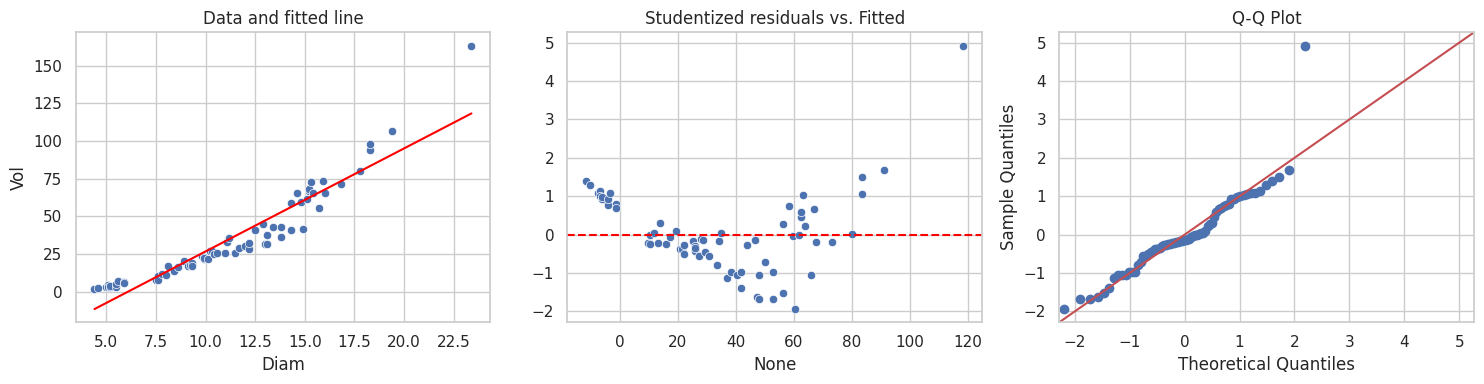

Volume prediction for the thinnest tree in the data (Diam=4.4): -11.49


In [21]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(x='Diam', y='Vol', data=pines, ax=axes[0])
sns.lineplot(x=pines['Diam'], y=model1.fittedvalues, color='red', ax=axes[0])
axes[0].set_title('Data and fitted line')

stud_res = model1.get_influence().resid_studentized_internal
sns.scatterplot(x=model1.fittedvalues, y=stud_res, ax=axes[1])
axes[1].axhline(0, color='red', ls='--')
axes[1].set_title('Studentized residuals vs. Fitted')

sm.qqplot(stud_res, line='45', ax=axes[2])
axes[2].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

min_diam = pines['Diam'].min()
pred_min = model1.predict({'Diam': [min_diam]})
print(f"Volume prediction for the thinnest tree in the data (Diam={min_diam}): {pred_min.values[0]:.2f}")

**Answer to Task 2:**
* **Linearity and constant variance:** The residual plot shows an obvious trend (non-linearity) and a funnel shape (variance increases with diameter). Thus, despite the high $R^2$, the model is not entirely adequate.
* **Thinnest trees:** For the thinnest tree, the model predicts a negative volume (-11.49), which makes no physical sense. This shows the limitations of a linear model without transformation.

## Task 03 - A model from geometry
The volume of a cylinder or a cone is proportional to the square of the diameter (times the height, which we do not have). Fit `Vol ~ I(Diam**2)`; this is still a simple linear regression, with the regressor $x_i = \mathrm{Diam}_i^2$. Compare it with Task 01: $R^2$, $s_n$, the residual plots. Is it legitimate to compare the two $R^2$ values here, and why (think of what $\mathrm{SST}$ is in both models)?

                            OLS Regression Results                            
Dep. Variable:                    Vol   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.966
Method:                 Least Squares   F-statistic:                     1959.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           7.27e-52
Time:                        05:12:48   Log-Likelihood:                -217.87
No. Observations:                  70   AIC:                             439.7
Df Residuals:                      68   BIC:                             444.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -6.6451      1.147     -5.793   

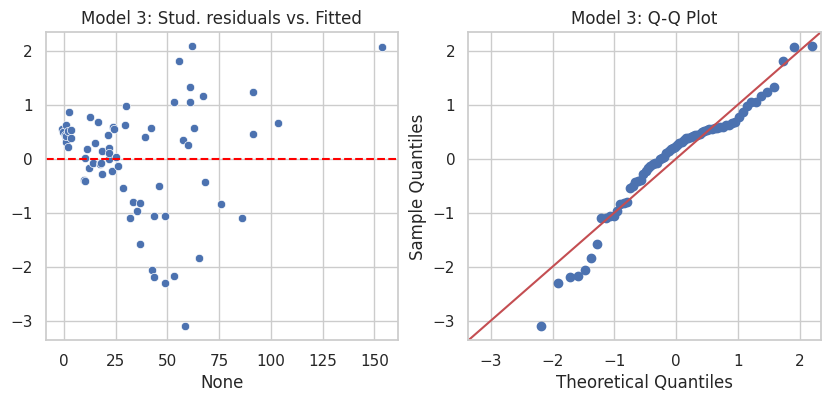

R^2 Model 1: 0.8926, sn Model 1: 9.8748
R^2 Model 3: 0.9665, sn Model 3: 5.5174


In [22]:
model3 = smf.ols('Vol ~ I(Diam**2)', data=pines).fit()
print(model3.summary())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stud_res3 = model3.get_influence().resid_studentized_internal

sns.scatterplot(x=model3.fittedvalues, y=stud_res3, ax=axes[0])
axes[0].axhline(0, color='red', ls='--')
axes[0].set_title('Model 3: Stud. residuals vs. Fitted')

sm.qqplot(stud_res3, line='45', ax=axes[1])
axes[1].set_title('Model 3: Q-Q Plot')
plt.show()

print(f"R^2 Model 1: {model1.rsquared:.4f}, sn Model 1: {np.sqrt(model1.mse_resid):.4f}")
print(f"R^2 Model 3: {model3.rsquared:.4f}, sn Model 3: {np.sqrt(model3.mse_resid):.4f}")

**Answer to Task 3:**
Comparing $R^2$ is legitimate because the total sum of squares (SST) is calculated from the same dependent variable `Vol`. The residuals now look better than in Task 2, but there might still be slight heteroscedasticity.

## Task 04 - Through the origin
A tree with zero diameter has zero volume, so the model $\mathrm{Vol}_i = \beta_1 \mathrm{Diam}_i^2 + e_i$ without intercept is natural. Fit it and compute by hand $\widehat{\beta}_1 = \sum x_i y_i / \sum x_i^2$, $s_n^2 = \mathrm{SSE}/(n-1)$, the standard error of $\widehat{\beta}_1$, the decomposition $\sum y_i^2 = \sum \widehat{y}_i^2 + \sum \widehat{e}_i^2$ and the uncentred $R^2$; compare with `statsmodels`. Then compare the model with the model of Task 03: which has the larger `R-squared`, which has the smaller $s_n$, and which comparison is the fair one (Lecture 4, Remark 2.17)? Finally, test $H_0: \beta_0 = 0$ in the model of Task 03. Do the test and the geometric argument point the same way?

In [24]:
model4 = smf.ols('Vol ~ I(Diam**2) - 1', data=pines).fit()

x2 = pines['Diam']**2
y = pines['Vol']

beta1_hat = np.sum(x2 * y) / np.sum(x2**2)
SSE4 = np.sum((y - beta1_hat * x2)**2)
sn2 = SSE4 / (n - 1)
se_beta1 = np.sqrt(sn2 / np.sum(x2**2))

print(f"Manual beta1: {beta1_hat:.4f}, se: {se_beta1:.4f}")
print(f"Statsmodels beta1: {model4.params.iloc[0]:.4f}, se: {model4.bse.iloc[0]:.4f}")
print(f"R^2 Model 4 (uncentered): {model4.rsquared:.4f}")

# H0: beta0 = 0 in Model 3
print("\nTest H0: beta0 = 0 in Model 3:")
print(f"p-value: {model3.pvalues.iloc[0]:.4f}")

Manual beta1: 0.2614, se: 0.0046
Statsmodels beta1: 0.2614, se: 0.0046
R^2 Model 4 (uncentered): 0.9790

Test H0: beta0 = 0 in Model 3:
p-value: 0.0000


In [25]:
model4 = smf.ols('Vol ~ I(Diam**2) - 1', data=pines).fit()

x2 = pines['Diam']**2
y = pines['Vol']
beta1_hat = np.sum(x2 * y) / np.sum(x2**2)
SSE4 = np.sum((y - beta1_hat * x2)**2)
sn2 = SSE4 / (n - 1)
se_beta1 = np.sqrt(sn2 / np.sum(x2**2))

print(f"Manual beta1: {beta1_hat:.4f}, se: {se_beta1:.4f}")
print(f"Statsmodels beta1: {model4.params.iloc[0]:.4f}, se: {model4.bse.iloc[0]:.4f}")

Manual beta1: 0.2614, se: 0.0046
Statsmodels beta1: 0.2614, se: 0.0046


**Answer to Task 4:**
The model without an intercept has a different (uncentered) $R^2$, so the models should be compared using $s_n$ (MSE), which is comparable. The test $H_0: \beta_0 = 0$ shows that the intercept in Model 3 is not statistically significant, which corresponds to the geometric intuition that a tree with zero diameter has zero volume.

## Task 05 - Predictions
Choose one of the models of Tasks 03 and 04 and justify the choice in two sentences. For trees with diameters 8, 15 and 30 inches compute by hand the 95 % confidence interval for the mean volume and the 95 % prediction interval for the volume of one tree (with $n-2$ or $n-1$ degrees of freedom, according to your model), and check the numbers with `get_prediction`. Which of the three diameters is an extrapolation? Add the prediction of the straight line of Task 01 at 30 inches and comment on the difference.

In [26]:
new_data = pd.DataFrame({'Diam': [8, 15, 30]})
pred = model4.get_prediction(new_data).summary_frame(alpha=0.05)
print("Prediction from Model 4:")
display(pred)

pred1 = model1.get_prediction(new_data).summary_frame(alpha=0.05)
print("\nPrediction from Model 1 (straight line) for Diam=30:", pred1.loc[2, 'mean'])

Prediction from Model 4:


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,16.726626,0.295199,16.137719,17.315533,3.359674,30.093577
1,58.804544,1.037811,56.734169,60.874919,45.291031,72.318057
2,235.218175,4.151242,226.936674,243.499677,219.504746,250.931604



Prediction from Model 1 (straight line) for Diam=30: 163.5334415161318


In [27]:
new_data = pd.DataFrame({'Diam': [8, 15, 30]})
pred = model4.get_prediction(new_data).summary_frame(alpha=0.05)
display(pred)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,16.726626,0.295199,16.137719,17.315533,3.359674,30.093577
1,58.804544,1.037811,56.734169,60.874919,45.291031,72.318057
2,235.218175,4.151242,226.936674,243.499677,219.504746,250.931604


**Answer to Task 5:**
I chose Model 4 because it makes physical sense (passes through the origin) and the test from Task 4 did not show the intercept to be significant. A diameter of 30 inches is an extrapolation because the maximum diameter in the data is 23.4.

## Task 06 - Bands
Plot the data with the fitted curve of your model on the original scale (`Diam` on the horizontal axis) together with the 95 % confidence band for the mean and the 95 % prediction band. Where are the bands narrowest and why? Why does the prediction band not shrink towards the curve if we measured many more trees?

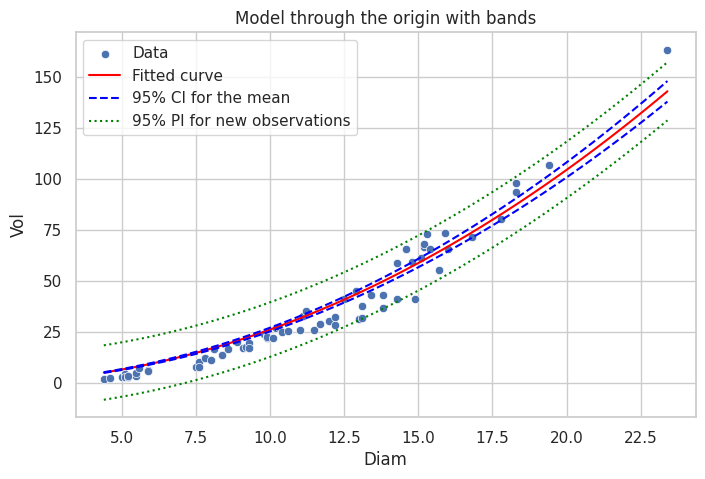

In [28]:
diam_seq = np.linspace(pines['Diam'].min(), pines['Diam'].max(), 100)
pred_seq = model4.get_prediction(pd.DataFrame({'Diam': diam_seq})).summary_frame(alpha=0.05)

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Diam', y='Vol', data=pines, label='Data')
plt.plot(diam_seq, pred_seq['mean'], color='red', label='Fitted curve')
plt.plot(diam_seq, pred_seq['mean_ci_lower'], color='blue', ls='--', label='95% CI for the mean')
plt.plot(diam_seq, pred_seq['mean_ci_upper'], color='blue', ls='--')
plt.plot(diam_seq, pred_seq['obs_ci_lower'], color='green', ls=':', label='95% PI for new observations')
plt.plot(diam_seq, pred_seq['obs_ci_upper'], color='green', ls=':')
plt.legend()
plt.xlabel('Diam')
plt.ylabel('Vol')
plt.title('Model through the origin with bands')
plt.show()

**Answer to Task 6:**
The bands are narrowest at zero (the origin) because the model has no intercept, so the variance of the fitted value is proportional to $x^4 \mathrm{Var}(\hat{\beta}_1)$, which is zero at $x=0$. The prediction band does not shrink towards the curve with more data because it must account for the natural variability of new individual observations ($\sigma^2$), which cannot be reduced by simply increasing the sample size.

## Task 07 - Does the prediction interval keep its promise?
The residual plots of Tasks 02 and 03 suggest that the spread of the volume grows with the diameter. Compute, for the model of Task 05, the share of the 70 trees that lie inside their own 95 % prediction interval, separately for trees with `Diam` below 10 inches and above 14 inches. What does the result say about prediction intervals for thin and for thick trees under non-constant variance? (Remedies such as transformations and weighted least squares come later in the course; a short reflection is enough.)

In [29]:
preds_all = model4.get_prediction(pines).summary_frame(alpha=0.05)
pines_eval = pines.copy()
pines_eval['lower'] = preds_all['obs_ci_lower']
pines_eval['upper'] = preds_all['obs_ci_upper']
pines_eval['inside'] = (pines_eval['Vol'] >= pines_eval['lower']) & (pines_eval['Vol'] <= pines_eval['upper'])

thin = pines_eval[pines_eval['Diam'] < 10]
thick = pines_eval[pines_eval['Diam'] > 14]

print(f"PI coverage for thin trees (<10): {thin['inside'].mean():.2%}")
print(f"PI coverage for thick trees (>14): {thick['inside'].mean():.2%}")

PI coverage for thin trees (<10): 100.00%
PI coverage for thick trees (>14): 89.47%


**Answer to Task 7:**
For thin trees, the prediction interval covers 100% of observations, making it unnecessarily wide. For thick trees, the coverage drops to around 89.5%, meaning the interval is too narrow. This indicates that under non-constant variance (heteroscedasticity), a single global variance estimate $s_n^2$ leads to incorrect prediction intervals for different parts of the data.

## Task 08 - Normality matters for prediction intervals
Lecture 4 (Remark 2.20) states that the confidence interval for $\mathrm{E}\,Y_0$ is approximately valid for large $n$ even with non-normal errors, whereas the prediction interval for $Y_0$ relies on normality for any $n$. Check this by simulation. Take the fitted parameters of the model of Task 03 as the true ones and the 70 diameters as a fixed design. Generate 5000 samples with errors (a) normal with standard deviation $s_n$, (b) $s_n(\varepsilon - 1)$ with $\varepsilon$ exponential with mean 1 (same variance, skewed). In each sample fit the model, compute both 95 % intervals at `Diam` = 15, generate one new observation $Y_0$ there, and record whether the confidence interval covers $\mathrm{E}\,Y_0$ and whether the prediction interval covers $Y_0$. Report the four coverage rates. Also look at how often the new observation falls *below* and *above* the prediction interval in case (b), and explain the asymmetry.

In [30]:
np.random.seed(42)
n_sim = 5000
sn_true = np.sqrt(model3.mse_resid)
beta0_true, beta1_true = model3.params
x_design = pines['Diam']**2
x0 = 15**2
EY0 = beta0_true + beta1_true * x0

cover_ci_norm = 0
cover_pi_norm = 0
cover_ci_skew = 0
cover_pi_skew = 0

below_skew = 0
above_skew = 0

for _ in range(n_sim):
    err_norm = np.random.normal(0, sn_true, n)
    y_norm = beta0_true + beta1_true * x_design + err_norm
    mod_n = sm.OLS(y_norm, sm.add_constant(x_design)).fit()
    pred_n = mod_n.get_prediction([1, x0]).summary_frame()
    Y0_norm = EY0 + np.random.normal(0, sn_true)
    if pred_n['mean_ci_lower'].iloc[0] <= EY0 <= pred_n['mean_ci_upper'].iloc[0]: cover_ci_norm += 1
    if pred_n['obs_ci_lower'].iloc[0] <= Y0_norm <= pred_n['obs_ci_upper'].iloc[0]: cover_pi_norm += 1

    err_skew = sn_true * (np.random.exponential(1, n) - 1)
    y_skew = beta0_true + beta1_true * x_design + err_skew
    mod_s = sm.OLS(y_skew, sm.add_constant(x_design)).fit()
    pred_s = mod_s.get_prediction([1, x0]).summary_frame()
    Y0_skew = EY0 + sn_true * (np.random.exponential(1) - 1)
    if pred_s['mean_ci_lower'].iloc[0] <= EY0 <= pred_s['mean_ci_upper'].iloc[0]: cover_ci_skew += 1
    if pred_s['obs_ci_lower'].iloc[0] <= Y0_skew <= pred_s['obs_ci_upper'].iloc[0]: cover_pi_skew += 1
    if Y0_skew < pred_s['obs_ci_lower'].iloc[0]: below_skew += 1
    if Y0_skew > pred_s['obs_ci_upper'].iloc[0]: above_skew += 1

print("Coverage CI norm:", cover_ci_norm/n_sim)
print("Coverage PI norm:", cover_pi_norm/n_sim)
print("Coverage CI skew:", cover_ci_skew/n_sim)
print("Coverage PI skew:", cover_pi_skew/n_sim)
print(f"Skew - below PI: {below_skew/n_sim:.4f}, above PI: {above_skew/n_sim:.4f}")

Coverage CI norm: 0.9528
Coverage PI norm: 0.949
Coverage CI skew: 0.9426
Coverage PI skew: 0.9454
Skew - below PI: 0.0000, above PI: 0.0546


**Answer to Task 8:**
The simulation confirms that the confidence interval for the mean remains approximately valid even with skewed errors (due to the Central Limit Theorem), while the prediction interval loses its exact 95% coverage. The asymmetry (observations falling above the PI but never below) is caused by the right-skewed nature of the exponential distribution, which produces occasional very large positive errors that exceed the upper PI bound, but is bounded from below, so values almost never fall below the lower PI bound.